In [18]:

import torch
from transformers import CLIPTokenizer, CLIPTextModel
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = CLIPTokenizer.from_pretrained(
    MODEL_ID,
    subfolder="tokenizer"
)

text_encoder = CLIPTextModel.from_pretrained(
    MODEL_ID,
    subfolder="text_encoder"
).to(device)

text_encoder.eval()


c:\Users\harsh\anaconda3\envs\agentic_ai\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\harsh\.cache\huggingface\hub\models--stable-diffusion-v1-5--stable-diffusion-v1-5. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\harsh\anaconda3\envs\agentic_ai\Lib\site-packages\huggingface_hub\file_down

CLIPTextModel(
  (embeddings): CLIPTextEmbeddings(
    (token_embedding): Embedding(49408, 768)
    (position_embedding): Embedding(77, 768)
  )
  (encoder): CLIPEncoder(
    (layers): ModuleList(
      (0-11): 12 x CLIPEncoderLayer(
        (self_attn): CLIPAttention(
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (out_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layer_norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): CLIPMLP(
          (activation_fn): QuickGELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear(in_features=3072, out_features=768, bias=True)
        )
        (layer_norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      )
    )
  )
  (fina

In [19]:
def embedding(text):
    inputs = tokenizer(
        text,
        padding="max_length",
        max_length=77,
        truncation=True,
        return_tensors="pt"
    )

    input_ids = inputs.input_ids.to(device)

    with torch.no_grad():
        text_embeddings = text_encoder(
            input_ids
        ).last_hidden_state

    return text_embeddings

In [7]:
from datasets import load_dataset
import os

# Download the dataset
dataset = load_dataset(
    "lambdalabs/naruto-blip-captions",
    split="train"
)

# Create output folders
os.makedirs("data/naruto/images", exist_ok=True)

# Save images and captions
with open("data/naruto/captions.txt", "w", encoding="utf-8") as f:
    for i, item in enumerate(dataset):
        image = item["image"].convert("RGB")
        caption = item["text"]

        filename = f"{i:05d}.png"
        image.save(f"data/naruto/images/{filename}")

        f.write(f"{filename}\t{caption}\n")

print("Download complete!")
print("Number of image-caption pairs:", len(dataset))
print("Saved to data/naruto/")


Repo card metadata block was not found. Setting CardData to empty.


Download complete!
Number of image-caption pairs: 1221
Saved to data/naruto/


In [9]:
import torch

print("CUDA available:",torch.cuda.is_available())
if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: NVIDIA GeForce RTX 5070 Laptop GPU


In [10]:
import torch 
from diffusers import AutoencoderKL

vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse",
                                     torch_dtype=torch.float16,).to("cuda")

vae.eval()
print("VAE LOADED SUCCESSFULLY")

c:\Users\harsh\anaconda3\envs\agentic_ai\Lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


VAE LOADED SUCCESSFULLY


In [23]:
import os
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

image_dir = "data/naruto/images"
caption_file = "data/naruto/captions.txt"

transform = transforms.Compose([
    transforms.Resize(512),
    transforms.CenterCrop(512),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3),
])

class NarutoDataset(Dataset):
    def __init__(self, image_dir, caption_file, transform):
        self.image_dir = image_dir
        self.transform = transform
        self.captions = {}

        with open(caption_file, "r", encoding="utf-8") as f:
            for line in f:
                line = line.rstrip("\n")
                if not line:
                    continue

                filename, caption = line.split("\t", 1)
                self.captions[filename] = caption

        self.image_files = sorted([
            filename for filename in self.captions
            if os.path.isfile(os.path.join(image_dir, filename))
        ])

        print("Matched image-caption pairs:", len(self.image_files))

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        filename = self.image_files[idx]
        image_path = os.path.join(self.image_dir, filename)

        with Image.open(image_path) as img:
            image = self.transform(img.convert("RGB"))

        caption = self.captions[filename]

        return image, caption


dataset = NarutoDataset(image_dir, caption_file, transform)

loader = DataLoader(
    dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
)

images, captions = next(iter(loader))

images = images.to("cuda")

print("Total images:", len(dataset))
print("Image batch shape:", images.shape)
print("Caption:", captions[0])

Matched image-caption pairs: 1221
Total images: 1221
Image batch shape: torch.Size([1, 3, 512, 512])
Caption: a woman with blonde hair and blue eyes


In [14]:
from diffusers import DDPMScheduler

scheduler = DDPMScheduler(
    num_train_timesteps=1000,
    beta_start=0.00085,
    beta_end=0.012,
    beta_schedule="linear",
    prediction_type="epsilon",
    clip_sample=False,
)

print("Scheduler created successfully")



Scheduler created successfully


In [16]:

IMAGE_DIR = "data/naruto/images"
CAPTION_FILE = "data/naruto/captions.txt"
OUTPUT_DIR = "outputs"

BATCH_SIZE = 1
NUM_EPOCHS = 5
LEARNING_RATE = 1e-4
from diffusers import UNet2DConditionModel
device = "cuda" if torch.cuda.is_available() else "cpu"

unet = UNet2DConditionModel(
    sample_size=512,
    in_channels=4,
    out_channels=4,
    down_block_types=(
        "CrossAttnDownBlock2D",
        "CrossAttnDownBlock2D",
        "CrossAttnDownBlock2D",
        "DownBlock2D"
    ),
    up_block_types=(
        "UpBlock2D",
        "CrossAttnUpBlock2D",
        "CrossAttnUpBlock2D",
        "CrossAttnUpBlock2D"
    ),
    block_out_channels=(128, 256, 512, 512),
    layers_per_block=2,
    cross_attention_dim=768,
    attention_head_dim=8,
    norm_num_groups=32,
).to(device)

unet.enable_gradient_checkpointing()
unet.train()

optimizer = torch.optim.AdamW(
    unet.parameters(),
    lr=LEARNING_RATE,
)
use_amp = device == "cuda"
scaler = torch.amp.GradScaler(
    "cuda", enabled=use_amp
)
print("U-NET model initialized")

U-NET model initialized


In [24]:
vae_dtype = (
    torch.float16 if device == "cuda"
    else torch.float32
)
import torch.nn.functional as F
for epoch in range(NUM_EPOCHS):
    total_loss = 0.0

    for step, (images, captions) in enumerate(loader):
        images = images.to(
            device=device,
            dtype=vae_dtype,
        )

        # A. Encode images into latent space.
        with torch.no_grad():
            latents = vae.encode(
                images
            ).latent_dist.sample()

            latents = (
                latents * vae.config.scaling_factor
            ).float()

            # B. Encode matching captions using YOUR CLIP.
            # Required output: [batch_size, 77, 768]
            text_embeddings = embedding(captions)
            text_embeddings = text_embeddings.to(
                device=device,
                dtype=torch.float32,
            )

        # Validate the embedding interface.
        assert text_embeddings.shape == (
            images.shape[0], 77, 768
        ), (
            "Expected CLIP embeddings with shape "
            "[B, 77, 768], got "
            f"{tuple(text_embeddings.shape)}"
        )
        noise = torch.randn_like(latents)

        timesteps = torch.randint(
            0,
            scheduler.config.num_train_timesteps,
            (images.shape[0],),
            device=device,
        ).long()

        noisy_latents = scheduler.add_noise(
            latents, noise, timesteps
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=use_amp,
        ):
            predicted_noise = unet(
                noisy_latents,
                timesteps,
                encoder_hidden_states=text_embeddings,
            ).sample

            loss = F.mse_loss(
                predicted_noise.float(),
                noise.float(),
            )

        # G. Update U-Net weights.
        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            unet.parameters(), 1.0
        )

        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

        if (step + 1) % 50 == 0:
            print(
                f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
                f"Step {step + 1}/{len(loader)} | "
                f"Loss: {loss.item():.5f}"
            )

    average_loss = total_loss / len(loader)

    print(
        f"Epoch {epoch + 1} complete | "
        f"Average loss: {average_loss:.5f}"
    )

    # H. Save a checkpoint after every epoch.
    checkpoint_dir = os.path.join(
        OUTPUT_DIR, f"unet_epoch_{epoch + 1}"
    )

    unet.save_pretrained(checkpoint_dir)

    torch.save(
        {
            "epoch": epoch + 1,
            "optimizer": optimizer.state_dict(),
            "scaler": scaler.state_dict(),
        },
        os.path.join(
            OUTPUT_DIR, f"training_state_{epoch + 1}.pt"
        ),
    )

print("Training finished!")


Epoch 1/5 | Step 50/1221 | Loss: 0.08599
Epoch 1/5 | Step 100/1221 | Loss: 0.12194
Epoch 1/5 | Step 150/1221 | Loss: 0.12223
Epoch 1/5 | Step 200/1221 | Loss: 0.03090
Epoch 1/5 | Step 250/1221 | Loss: 0.05015
Epoch 1/5 | Step 300/1221 | Loss: 1.16444
Epoch 1/5 | Step 350/1221 | Loss: 0.11049
Epoch 1/5 | Step 400/1221 | Loss: 0.04024
Epoch 1/5 | Step 450/1221 | Loss: 0.01343
Epoch 1/5 | Step 500/1221 | Loss: 0.43264
Epoch 1/5 | Step 550/1221 | Loss: 0.01704
Epoch 1/5 | Step 600/1221 | Loss: 0.33324
Epoch 1/5 | Step 650/1221 | Loss: 0.07111
Epoch 1/5 | Step 700/1221 | Loss: 0.19555
Epoch 1/5 | Step 750/1221 | Loss: 0.01805
Epoch 1/5 | Step 800/1221 | Loss: 0.24513
Epoch 1/5 | Step 850/1221 | Loss: 0.05806
Epoch 1/5 | Step 900/1221 | Loss: 0.03369
Epoch 1/5 | Step 950/1221 | Loss: 0.00977
Epoch 1/5 | Step 1000/1221 | Loss: 0.00863
Epoch 1/5 | Step 1050/1221 | Loss: 0.38797
Epoch 1/5 | Step 1100/1221 | Loss: 0.04962
Epoch 1/5 | Step 1150/1221 | Loss: 0.65385
Epoch 1/5 | Step 1200/1221 | Lo

In [25]:
import os
import torch

save_dir = "outputs/naruto_unet"
os.makedirs(save_dir, exist_ok=True)

unet.save_pretrained(save_dir)

print("Trained U-Net saved to:", save_dir)

Trained U-Net saved to: outputs/naruto_unet


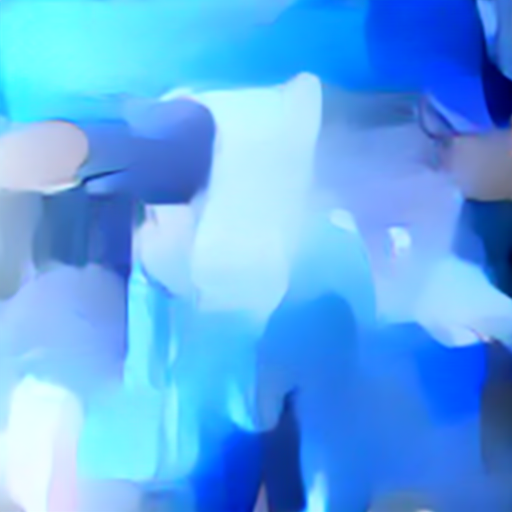

In [28]:
import torch
from PIL import Image
from IPython.display import display

device = "cuda"

unet.eval()
vae.eval()
text_encoder.eval()

prompt = "Human with Orange outfit"

# Convert text into embeddings
tokens = tokenizer(
    [prompt],
    padding="max_length",
    truncation=True,
    max_length=77,
    return_tensors="pt",
)

with torch.no_grad():
    text_output = text_encoder(tokens.input_ids.to(device))

    if isinstance(text_output, torch.Tensor):
        text_embeddings = text_output
    elif hasattr(text_output, "last_hidden_state"):
        text_embeddings = text_output.last_hidden_state
    else:
        text_embeddings = text_output[0]

    text_embeddings = text_embeddings.to(
        device=device,
        dtype=next(unet.parameters()).dtype,
    )

    # Start with random latent noise
    latents = torch.randn(
        (1, 4, 64, 64),
        device=device,
        dtype=next(unet.parameters()).dtype,
    )

    # Gradually remove noise
    scheduler.set_timesteps(50, device=device)

    for t in scheduler.timesteps:
        latent_input = scheduler.scale_model_input(latents, t)

        predicted_noise = unet(
            latent_input,
            t,
            encoder_hidden_states=text_embeddings,
        ).sample

        latents = scheduler.step(
            predicted_noise, t, latents
        ).prev_sample

    # Decode the final latent into an image
    latents = latents / vae.config.scaling_factor

    decoded = vae.decode(
        latents.to(dtype=next(vae.parameters()).dtype)
    ).sample

    decoded = (decoded / 2 + 0.5).clamp(0, 1)

    image_array = (
        decoded[0].permute(1, 2, 0).float().cpu().numpy() * 255
    ).round().astype("uint8")

    result = Image.fromarray(image_array)

display(result)